In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import torchvision.transforms as transforms
import torch
import os
import matplotlib.pyplot as plt
from PIL import Image
import torchvision

import numpy as np
from typing import Any, Dict, Optional, Union
import warnings
import cv2
from typing import Dict, List, Tuple, Union
from matplotlib.colors import LinearSegmentedColormap
from captum.attr import visualization as viz
from embedding_utils import *
from torchvision.models.feature_extraction import create_feature_extractor
from sklearn.manifold import TSNE, MDS
from math import ceil


/BS/feature_viz/work/micromamba/envs/envs/myenv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [4]:
classes_emb = [152, 153, 154, 155, 157]
num_real_img = 500

images_real, targets_real = obtain_num_images(class_number=classes_emb, num_img=num_real_img)
images_real.shape

torch.Size([2500, 3, 224, 224])

In [5]:
colors_per_class = {
    152 : [255, 0, 0],
    153 : [0, 255, 0],
    154 : [0, 0, 255],
    155 : [255, 0, 255],
    157 : [0, 255, 255],
   10152 : [179, 43, 43], #ours
    10153 : [43, 179, 43],
    10154 : [56, 56, 162],
    10155 : [166, 65, 166],
    10157 : [51, 182, 182],

    40152 : [179, 43, 43], #vital
    40153 : [43, 179, 43],
    40154 : [56, 56, 162],
    40155 : [166, 65, 166],
    40157 : [51, 182, 182],
}

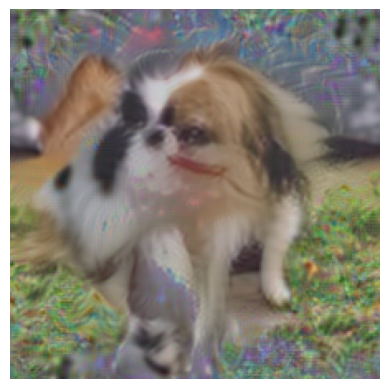

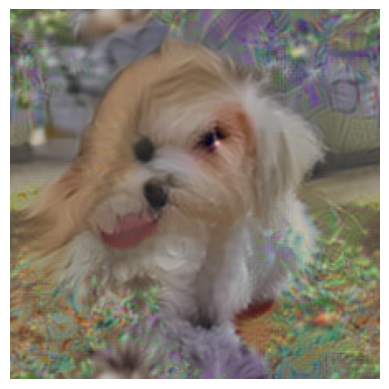

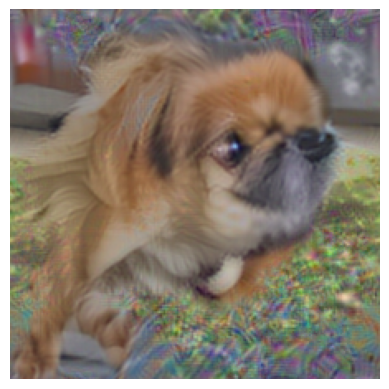

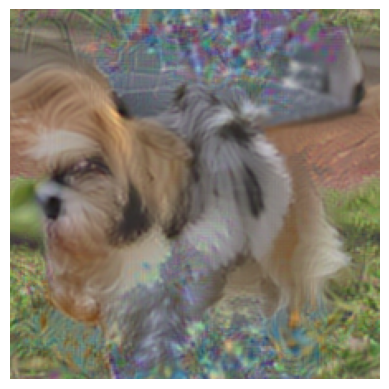

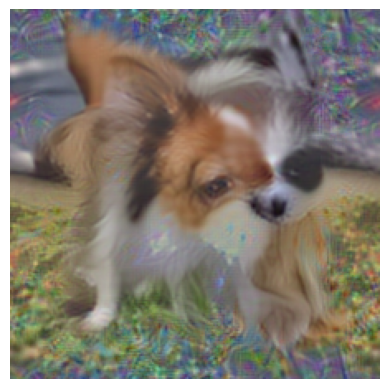

In [6]:
inputs_ours = []
target_ours = []

for cls_id in classes_emb:

    file = f'/BS/feature_viz/work/results/vitl16_graphMatching/vit16/cls{cls_id}/t1/c1_1_l1_1_l2_1_l3_1_l4_1.png'

    img, image_syn = load_image(filename=file,
                                isSyn=True,
                                debug=True)

    plt.show()
    
    inputs_ours.append(image_syn)

    target_syn = torch.tensor(10000+cls_id).unsqueeze(0)

    target_ours.append(target_syn)


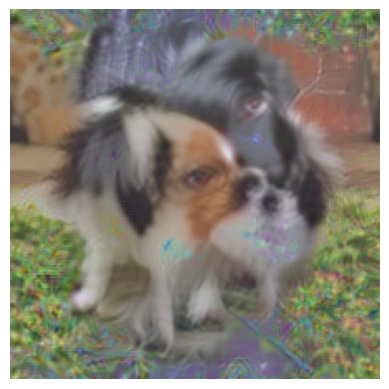

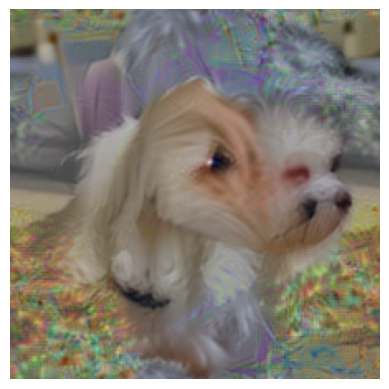

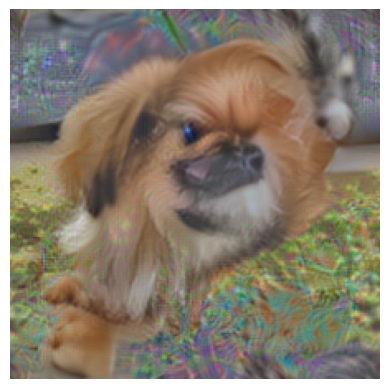

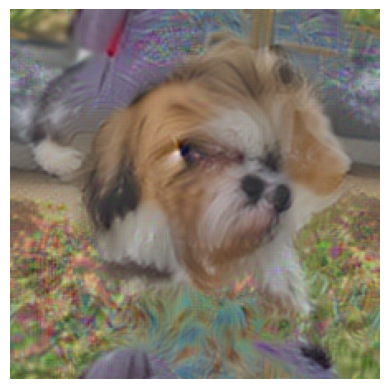

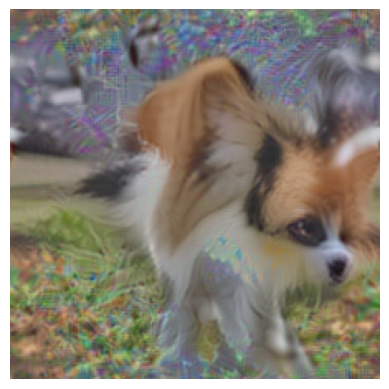

In [7]:
for cls_id in classes_emb:

    file = f'/BS/feature_viz/work/results/VITAL_ViT/vit-l-16/VITAL/cls{cls_id}/t1/c1_1.0_l1_1.0_l2_1.0_l3_1.0_l4_1.0.png'

    img, image_syn = load_image(filename=file,
                                isSyn=True,
                                debug=True)

    plt.show()
    
    inputs_ours.append(image_syn)

    target_syn = torch.tensor(40000+cls_id).unsqueeze(0)

    target_ours.append(target_syn)

target_ours = torch.cat(target_ours, dim=0)
inputs_ours = torch.cat(inputs_ours, dim=0)

In [8]:
model = models.__dict__['vit_l_16'](pretrained=True).eval()

return_nodes = {
                "conv_proj": "conv1",
                "encoder.layers.encoder_layer_2": "layer1",
                "encoder.layers.encoder_layer_9": "layer2",
                "encoder.layers.encoder_layer_20": "layer3",
                "encoder.layers.encoder_layer_23": "layer4",
                "heads.head": "fc"
            }

model2 = create_feature_extractor(model, return_nodes=return_nodes)
model2 = model2.eval()
model2 = model2.to(device)

/BS/feature_viz/work/micromamba/envs/envs/myenv/lib/python3.11/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/BS/feature_viz/work/micromamba/envs/envs/myenv/lib/python3.11/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ViT_L_16_Weights.IMAGENET1K_V1`. You can also use `weights=ViT_L_16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [9]:
data = torch.cat((inputs_ours, images_real))
targets = torch.cat((target_ours, targets_real))
batch_size = 64

nb_batchs = ceil(len(data) / batch_size)
start_ids = [i*batch_size for i in range(nb_batchs)]

results = []

with torch.no_grad():
    for i in start_ids:
        x = torch.tensor(data[i:i+batch_size])
        x = x.to(device)

        results.append(model2(x)["layer4"].cpu())

results = torch.cat(results)

/BS/feature_viz/work/storage/ssuhas/tmp/ipykernel_2066455/3708005147.py:12: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x = torch.tensor(data[i:i+batch_size])


In [10]:
results.shape

torch.Size([2510, 197, 1024])

In [11]:
results_mean = results.mean(dim=1)

In [12]:
embeddings = TSNE(n_components=2,random_state=5).fit_transform(results_mean.detach().numpy())
embeddings.shape

(2510, 2)

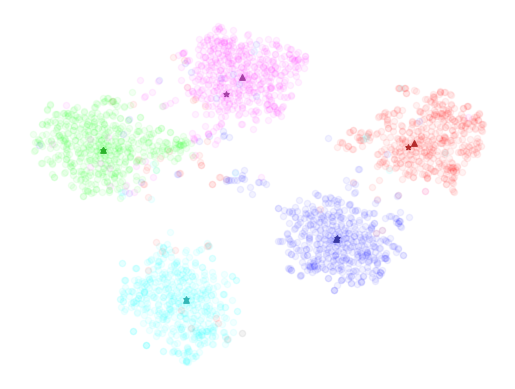

In [13]:
visualizeEmbeddingPoints(embeddings, targets.cpu().detach().numpy(),  colors_per_class=colors_per_class, filename='vitl32_embedding.png')